# Az eredmények elemzése

A `results/results.csv` fájl a teljes kísérletsorozat eredményét tartalmazza (10 ismétlés). A notebook a négy kutatási kérdésre válaszol, az ábrákat a `results/` mappába is elmenti.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

r = pd.read_csv("../results/results.csv")
r["rate_pct"] = (r["rate"] * 100).round().astype(int)
r["jellemzok"] = r["use_grades"].map({True: "G1/G2-vel", False: "G1/G2 nélkül"})
r["imputer"] = r["imputer"].replace(
    {"mean_mode": "átlag/módusz", "knn": "KNN", "iterative": "iteratív", "none": "nincs"}
)
r["model"] = r["model"].replace(
    {"ridge": "Ridge", "random_forest": "Random forest", "gradient_boosting": "Gradient boosting"}
)

base = r[r["rate"] == 0]
miss = r[r["rate"] > 0]

print(r.shape, "-", r["seed"].nunique(), "ismétlés")

(1860, 12) - 10 ismétlés


## Alapeset: hiány nélkül

Ez a felső korlát: ennél jobb eredményt hiányos adattal nem várhatunk. A `G1`/`G2` jegyekkel a modellek sokkal pontosabbak, mert a korábbi jegyek szinte elárulják a végső jegyet.

In [4]:
base.groupby(["jellemzok", "model"])[["rmse", "r2"]].agg(["mean", "std"]).round(2)

rmse          r2      
                                mean   std  mean   std
jellemzok    model                                    
G1/G2 nélkül Gradient boosting  2.78  0.29  0.24  0.07
             Random forest      2.75  0.28  0.25  0.06
             Ridge              2.77  0.27  0.24  0.05
G1/G2-vel    Gradient boosting  1.27  0.24  0.84  0.04
             Random forest      1.24  0.23  0.85  0.04
             Ridge              1.24  0.23  0.85  0.04

## 1. kérdés: mennyit romlik a teljesítmény a hiányarány növekedésével?

A 0% az alapeset. A többi pontnál az átlag az összes imputációs módszeren és mindkét hiánytípuson át készült.

In [5]:
osszes = pd.concat([base, miss])

tab = osszes.pivot_table(
    index=["jellemzok", "model"], columns="rate_pct", values="rmse", aggfunc="mean"
).round(2)
tab

rate_pct                          0     5     10    20    30    40
jellemzok    model                                                
G1/G2 nélkül Gradient boosting  2.78  2.80  2.83  2.88  2.93  3.02
             Random forest      2.75  2.76  2.79  2.85  2.89  2.94
             Ridge              2.77  2.79  2.83  2.88  2.92  2.99
G1/G2-vel    Gradient boosting  1.27  1.35  1.40  1.62  1.82  2.01
             Random forest      1.24  1.35  1.42  1.61  1.78  1.97
             Ridge              1.24  1.35  1.44  1.65  1.84  2.01

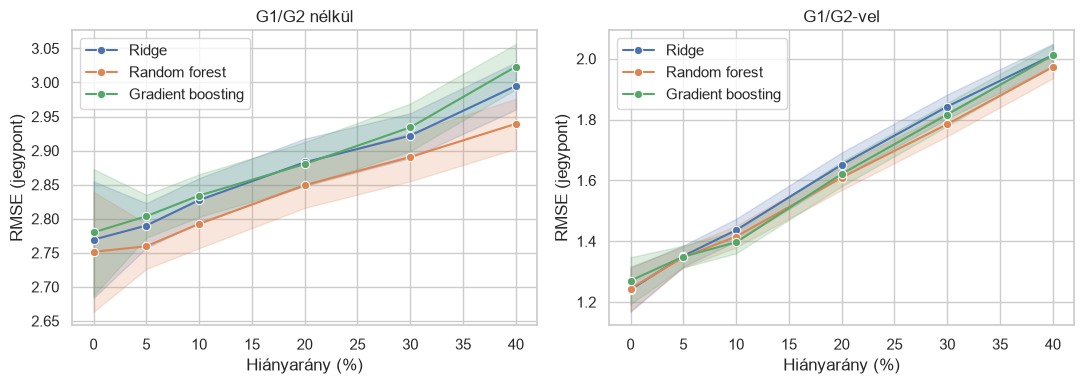

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (nev, d) in zip(axes, osszes.groupby("jellemzok")):
    sns.lineplot(data=d, x="rate_pct", y="rmse", hue="model", marker="o", errorbar="se", ax=ax)
    ax.set_title(nev)
    ax.set_xlabel("Hiányarány (%)")
    ax.set_ylabel("RMSE (jegypont)")
    ax.legend(title=None)
plt.tight_layout()
plt.savefig("../results/q1_rmse_hianyarany.png", dpi=150, bbox_inches="tight")
plt.show()

## 2. kérdés: melyik imputációs módszer a legjobb?

Minden sor egy hiánytípus és hiányarány, az értékek az átlagos RMSE-k (kisebb a jobb), a három modell és a 10 ismétlés átlaga.

In [7]:
q2 = miss.pivot_table(
    index=["jellemzok", "mechanism", "rate_pct"], columns="imputer", values="rmse"
)
q2["legjobb"] = q2.idxmin(axis=1)
q2.round(2)

imputer                           KNN  iteratív  átlag/módusz       legjobb
jellemzok    mechanism rate_pct                                            
G1/G2 nélkül MAR       5         2.78      2.78          2.77  átlag/módusz
                       10        2.82      2.82          2.81  átlag/módusz
                       20        2.92      2.91          2.89  átlag/módusz
                       30        2.90      2.94          2.94           KNN
                       40        2.98      3.00          2.98           KNN
             MCAR      5         2.81      2.79          2.78  átlag/módusz
                       10        2.83      2.81          2.81      iteratív
                       20        2.85      2.83          2.82  átlag/módusz
                       30        2.92      2.91          2.89  átlag/módusz
                       40        2.99      3.02          2.95  átlag/módusz
G1/G2-vel    MAR       5         1.34      1.32          1.36      iteratív
                       10        1.43      1.35          1.44      iteratív
                       20        1.69      1.56          1.66      iteratív
                       30        1.89      1.81          1.84      iteratív
                       40        2.09      2.02          2.04      iteratív
             MCAR      5         1.35      1.32          1.40      iteratív
                       10        1.45      1.37          1.46      iteratív
                       20        1.70      1.52          1.63      iteratív
                       30        1.84      1.71          1.80      iteratív
                       40        2.02      1.88          1.93      iteratív

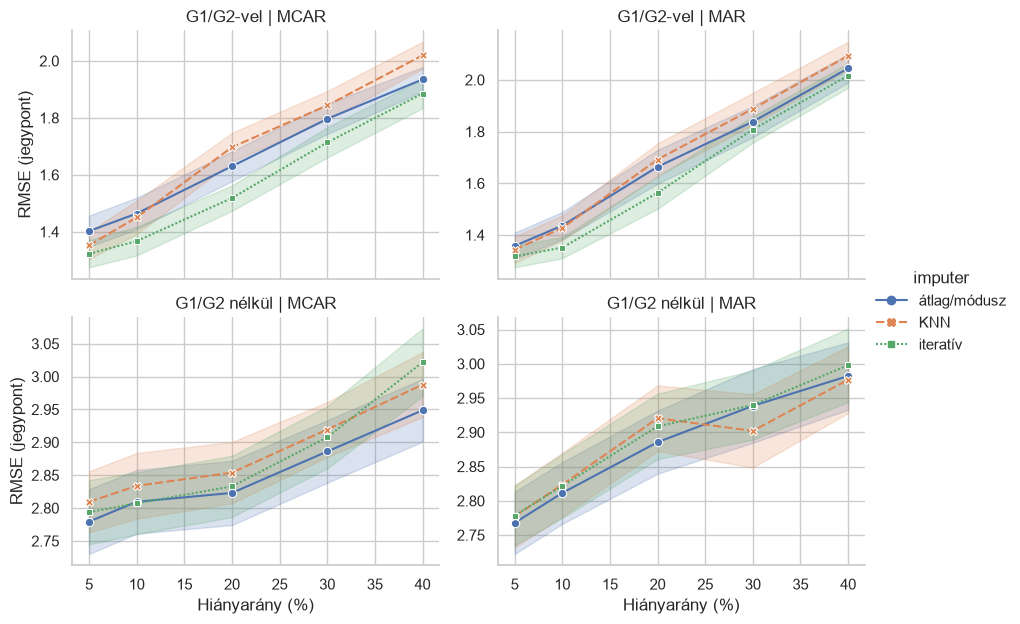

In [8]:
g = sns.relplot(
    data=miss, x="rate_pct", y="rmse", hue="imputer", style="imputer", markers=True,
    kind="line", col="mechanism", row="jellemzok", errorbar="se",
    height=3.2, aspect=1.4, facet_kws={"sharey": False},
)
g.set_axis_labels("Hiányarány (%)", "RMSE (jegypont)")
g.set_titles("{row_name} | {col_name}")
g.savefig("../results/q2_imputerek.png", dpi=150, bbox_inches="tight")
plt.show()

Az átlagok közti különbségek kicsik, ezért páros összehasonlítást is lészítek. Ugyanazt a hiányt és ugyanazt a tanító/teszt felosztást kapja mindhárom módszer, tehát a különbség csak a módszerből jöhet. A táblázat azt mutatja, mennyivel tér el a RMSE az átlag/módusz módszerhez képest (negatív = jobb nála), és a hiányarány-ismétlés párok hány százalékában jobb.

In [ ]:
p = miss.pivot_table(
    index=["jellemzok", "mechanism", "rate", "model", "seed"], columns="imputer", values="rmse"
)

sorok = []
for (nev, mech), d in p.groupby(level=["jellemzok", "mechanism"]):
    for modszer in ["iteratív", "KNN"]:
        diff = (d[modszer] - d["átlag/módusz"]).groupby(level=["rate", "seed"]).mean()
        sorok.append({
            "jellemzők": nev,
            "hiánytípus": mech,
            "összehasonlítás": f"{modszer} - átlag/módusz",
            "átlagos különbség": round(diff.mean(), 3),
            "az esetek hány %-ában jobb": round((diff < 0).mean() * 100),
        })
pd.DataFrame(sorok)

,jellemzők,hiánytípus,összehasonlítás,átlagos különbség,az esetek hány %-ában jobb
0,G1/G2 nélkül,MAR,iteratív - átlag/módusz,0.012,40
1,G1/G2 nélkül,MAR,KNN - átlag/módusz,0.003,50
2,G1/G2 nélkül,MCAR,iteratív - átlag/módusz,0.023,36
3,G1/G2 nélkül,MCAR,KNN - átlag/módusz,0.032,34
4,G1/G2-vel,MAR,iteratív - átlag/módusz,-0.057,80
5,G1/G2-vel,MAR,KNN - átlag/módusz,0.021,32
6,G1/G2-vel,MCAR,iteratív - átlag/módusz,-0.084,88
7,G1/G2-vel,MCAR,KNN - átlag/módusz,0.027,48


### Az imputált értékek pontossága

`imp_nrmse`: a számoszlopokon a hiba az oszlop szórásának többszöröseként (az 1,0 azt jelenti, hogy az imputáció annyit téved, mintha az átlagot írnánk be, kisebb a jobb). `imp_acc`: a kategorikus oszlopokon az eltalált értékek aránya (nagyobb a jobb).

In [10]:
miss.groupby(["mechanism", "imputer"])[["imp_nrmse", "imp_acc"]].mean().round(2)

imp_nrmse  imp_acc
mechanism imputer                         
MAR       KNN                1.01     0.64
          iteratív           0.95     0.67
          átlag/módusz       1.01     0.68
MCAR      KNN                1.00     0.65
          iteratív           0.94     0.67
          átlag/módusz       1.00     0.69

## 3. kérdés: van-e kölcsönhatás az imputáció és a modell között?

Először a nyers RMSE-k imputer × modell bontásban. Ha nincs kölcsönhatás, az imputerek sorrendje minden modellnél ugyanaz.

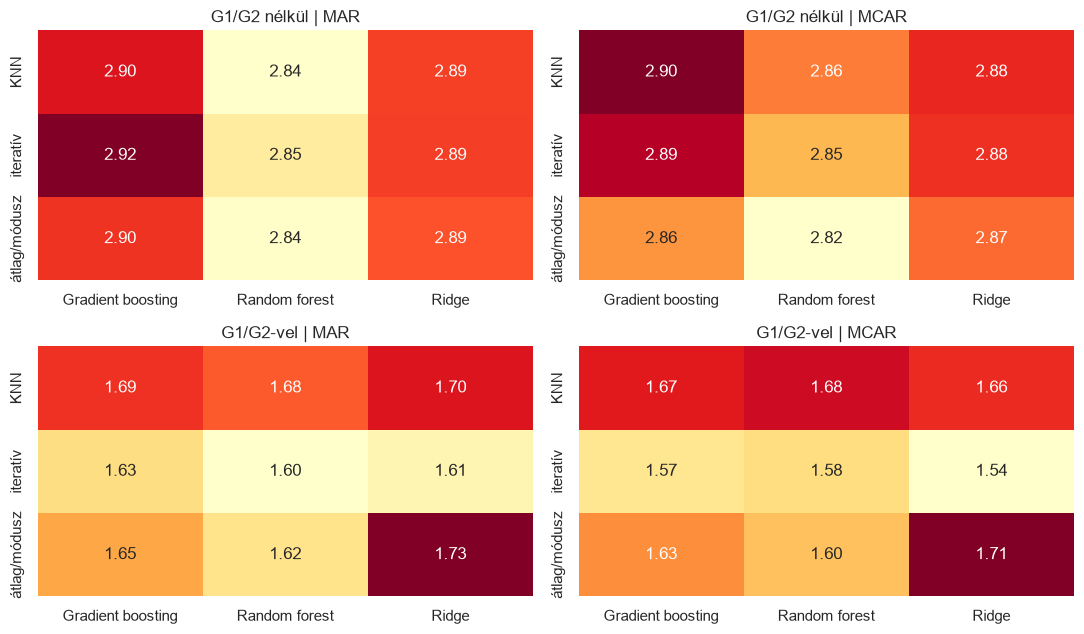

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6.5))
for i, (nev, d1) in enumerate(miss.groupby("jellemzok")):
    for j, (mech, d2) in enumerate(d1.groupby("mechanism")):
        x = d2.pivot_table(index="imputer", columns="model", values="rmse")
        sns.heatmap(x, annot=True, fmt=".2f", cmap="YlOrRd", cbar=False, ax=axes[i, j])
        axes[i, j].set_title(f"{nev} | {mech}")
        axes[i, j].set_xlabel("")
        axes[i, j].set_ylabel("")
plt.tight_layout()
plt.savefig("../results/q3_hotermap_rmse.png", dpi=150, bbox_inches="tight")
plt.show()

A kölcsönhatás tisztán akkor látszik, ha kivonjuk belőle a módszer és a modell önálló hatását. Minden cella értéke: `RMSE - sorátlag - oszlopátlag + főátlag`. A 0 körüli értékek azt jelentik, hogy nincs kölcsönhatás, a pozitív érték azt, hogy az adott párosítás a várhatónál rosszabb, a negatív, hogy jobb.

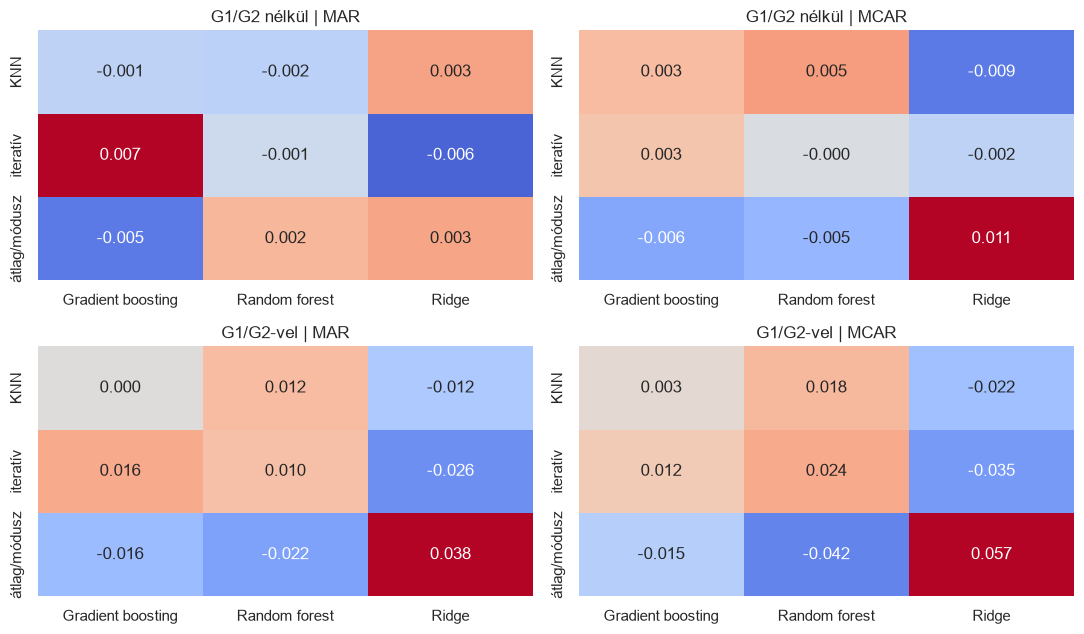

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6.5))
for i, (nev, d1) in enumerate(miss.groupby("jellemzok")):
    for j, (mech, d2) in enumerate(d1.groupby("mechanism")):
        x = d2.pivot_table(index="imputer", columns="model", values="rmse")
        inter = x.sub(x.mean(axis=1), axis=0).sub(x.mean(axis=0), axis=1) + x.values.mean()
        sns.heatmap(inter, annot=True, fmt=".3f", cmap="coolwarm", center=0, cbar=False, ax=axes[i, j])
        axes[i, j].set_title(f"{nev} | {mech}")
        axes[i, j].set_xlabel("")
        axes[i, j].set_ylabel("")
plt.tight_layout()
plt.savefig("../results/q3_kolcsonhatas.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. kérdés: összefügg-e az imputáció pontossága a modell teljesítményével?

A hiányarány mindkettőre hat, ezért a korrelációt csak az azonos hiányarányú, hiánytípusú és modellű futásokon belül nézzük (előbb kivonjuk a csoportátlagot). Így azt mérjük, hogy az azonos körülmények közti ingadozás összefügg-e.

In [13]:
kulcs = ["jellemzok", "model", "mechanism", "rate"]
d = miss.copy()
for oszlop in ["imp_nrmse", "imp_acc", "rmse"]:
    d[oszlop + "_elteres"] = d[oszlop] - d.groupby(kulcs)[oszlop].transform("mean")

sorok = []
for (nev, modell), g in d.groupby(["jellemzok", "model"]):
    sorok.append({
        "jellemzők": nev,
        "modell": modell,
        "imp_nrmse - RMSE": round(g["imp_nrmse_elteres"].corr(g["rmse_elteres"]), 2),
        "imp_acc - RMSE": round(g["imp_acc_elteres"].corr(g["rmse_elteres"]), 2),
    })
pd.DataFrame(sorok)

,jellemzők,modell,imp_nrmse - RMSE,imp_acc - RMSE
0,G1/G2 nélkül,Gradient boosting,-0.09,-0.08
1,G1/G2 nélkül,Random forest,-0.10,-0.06
2,G1/G2 nélkül,Ridge,-0.06,-0.09
3,G1/G2-vel,Gradient boosting,0.16,-0.06
4,G1/G2-vel,Random forest,0.13,-0.10
5,G1/G2-vel,Ridge,0.20,-0.00


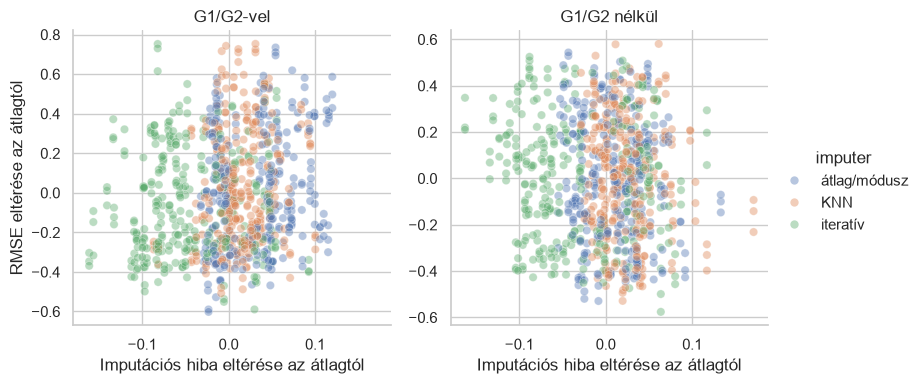

In [14]:
g = sns.relplot(
    data=d, x="imp_nrmse_elteres", y="rmse_elteres", hue="imputer",
    col="jellemzok", kind="scatter", alpha=0.4, height=4, facet_kws={"sharey": False},
)
g.set_axis_labels("Imputációs hiba eltérése az átlagtól", "RMSE eltérése az átlagtól")
g.set_titles("{col_name}")
g.savefig("../results/q4_imputacio_vs_rmse.png", dpi=150, bbox_inches="tight")
plt.show()